# Лабораторная работа №2. Классификация на Titanic

**Цель:** пройти полный цикл решения задачи классификации — от анализа данных и baseline до сравнения алгоритмов, анализа метрик, ошибок и важности признаков.

**Данные:** Titanic Dataset (https://www.kaggle.com/datasets/yasserh/titanic-dataset)
**Целевая переменная:** `Survived` (1 — выжил, 0 — нет)
**Основная метрика:** F1-score для класса `Survived = 1`. Порог качества: **F1 > 0.70**.
**Все модели обучаются и оцениваются на одном и том же разбиении** (`random_state=42`, `stratify=y`). Тестовая выборка используется только для финальной оценки.

### Структура работы
1. Первичный анализ данных (EDA)
2. Подготовка данных и выборок (ColumnTransformer, Pipeline)
3. Dummy baseline и leaderboard
4. Пять моделей: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN
5. Честное сравнение и confusion matrix
6. Feature importance
7. Анализ ошибок лучшей модели
8. Проверка на утечку информации
9. Выводы

## 1. Импорты и настройки

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
np.random.seed(RANDOM_STATE)

print("Библиотеки загружены.")

Библиотеки загружены.


## 2. Загрузка данных

In [3]:
# Путь к датасету; при необходимости измените.
DATA_PATH = r"C:\Users\serge\Downloads\Titanic-Dataset.csv"

df = pd.read_csv(DATA_PATH)
print("Размер датасета:", df.shape)
df.head()

Размер датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Первичный анализ данных

Проверим:
- типы признаков и распределение целевой переменной;
- пропуски и дубликаты;
- признаки, требующие отдельной обработки;
- признаки, использование которых может привести к утечке информации или бессмысленному запоминанию объектов.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
print("Пропуски по колонкам (шт., %):")
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2)
})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

Пропуски по колонкам (шт., %):


,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Число полных дубликатов строк: 0

Распределение целевой переменной Survived:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


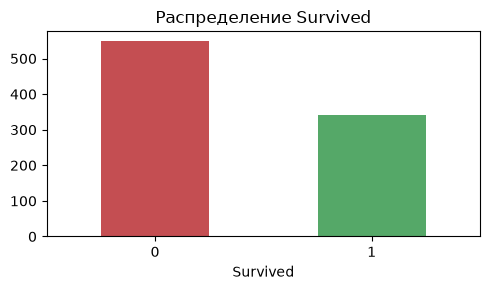

In [6]:
print("Число полных дубликатов строк:", df.duplicated().sum())

print("\nРаспределение целевой переменной Survived:")
print(df["Survived"].value_counts(normalize=True).round(3))

df["Survived"].value_counts().plot(kind="bar", color=["#c44e52", "#55a868"], figsize=(5, 3))
plt.title("Распределение Survived")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Типы и уникальность значений по категориальным колонкам
for col in ["Sex", "Embarked", "Pclass", "SibSp", "Parch"]:
    print(f"{col}:", df[col].value_counts(dropna=False).to_dict())

Sex: {'male': 577, 'female': 314}
Embarked: {'S': 644, 'C': 168, 'Q': 77, nan: 2}
Pclass: {3: 491, 1: 216, 2: 184}
SibSp: {0: 608, 1: 209, 2: 28, 4: 18, 3: 16, 8: 7, 5: 5}
Parch: {0: 678, 1: 118, 2: 80, 5: 5, 3: 5, 4: 4, 6: 1}


In [8]:
# Проверим признаки, которые потенциально "идентифицируют" пассажира
print("Уникальных PassengerId:", df["PassengerId"].nunique(), "из", len(df))
print("Уникальных Name:", df["Name"].nunique(), "из", len(df))
print("Уникальных Ticket:", df["Ticket"].nunique(), "из", len(df))
print("Уникальных Cabin:", df["Cabin"].nunique(), "из", len(df), "; пропусков:", df["Cabin"].isna().sum())

Уникальных PassengerId: 891 из 891
Уникальных Name: 891 из 891
Уникальных Ticket: 681 из 891
Уникальных Cabin: 147 из 891 ; пропусков: 687


### Выводы по первичному анализу данных

- **Размер и структура:** В датасете 891 строка и 12 колонок. Пропусков и дубликатов строк нет (0 полных дубликатов).
- **Целевая переменная (`Survived`):** Присутствует дисбаланс классов. Погибших (0) — 61.6%, выживших (1) — 38.4%. Это означает, что Accuracy здесь обманчива: модель, которая всегда предсказывает 0, даст точность 61.6%, но при этом не найдет ни одного выжившего (Recall = 0). Основная метрика — F1 для класса 1.
- **Пропуски в данных:**
  - `Cabin` — 687 пропусков (77.1%). Слишком много, восстанавливать нецелесообразно, **удалим признак**.
  - `Age` — 177 пропусков (19.87%). Числовой признак, заполним **медианой** (устойчива к выбросам).
  - `Embarked` — всего 2 пропуска (0.22%). Категориальный признак, заполним **модой**.
- **Признаки, приводящие к утечке или переобучению (удаляем):**
  - `PassengerId` — уникален (891 из 891), это просто номер.
  - `Name` — уникально (891 из 891). Если оставить как есть, модель просто запомнит каждого пассажира (переобучение).
  - `Ticket` — почти уникален (681 из 891 уникальных значений). Случайный набор букв и цифр, не несет обобщающей информации.
  - `Cabin` — 147 уникальных значений на 204 непустых строки. Фактически тоже идентификатор каюты.
- **Категориальные и числовые признаки:**
  - `Sex` (male: 577, female: 314) и `Embarked` (S, C, Q) требуют кодирования (One-Hot Encoding).
  - `Pclass` (1, 2, 3), `SibSp` и `Parch` — числовые (порядковые), их можно использовать как есть.

## 4. Подготовка данных и выборок

**План:**
1. Отбросить признаки-идентификаторы и признаки с утечкой (`PassengerId`, `Name`, `Ticket`, `Cabin`).
2. Отделить целевую переменную `Survived` от `X`.
3. Разделить данные на train/test с `stratify=y` и `random_state=42`.
4. Все преобразования обернуть в `Pipeline`/`ColumnTransformer`, чтобы параметры (медиана, мода, scaler) обучались **только на train**.

**Числовые признаки:** `Age`, `Fare`, `SibSp`, `Parch`.
**Категориальные:** `Sex`, `Embarked`, `Pclass` (Pclass оставим числовым — это порядковый код 1/2/3; можно и one-hot, но обычно информативнее как ordinal).

**Масштабирование:**
- Деревья (DT/RF/GB) **не требуют** масштабирования — работают с порогами по отдельным признакам.
- **SVM и KNN — требуют**, т.к. основаны на расстояниях / геометрии пространства: без масштабирования `Fare` (десятки-сотни) полностью подавит `Age` (десятки) и `SibSp` (0–8).

In [9]:
FEATURES_TO_DROP = ["PassengerId", "Name", "Ticket", "Cabin", "Survived"]

X = df.drop(columns=FEATURES_TO_DROP)
y = df["Survived"]

num_features = ["Age", "Fare", "SibSp", "Parch"]
cat_features = ["Sex", "Embarked", "Pclass"]

print("Числовые:", num_features)
print("Категориальные:", cat_features)
print("Размер X:", X.shape)

Числовые: ['Age', 'Fare', 'SibSp', 'Parch']
Категориальные: ['Sex', 'Embarked', 'Pclass']
Размер X: (891, 7)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| доля выживших:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| доля выживших:", round(y_test.mean(), 3))

Train: (712, 7) | доля выживших: 0.383
Test:  (179, 7) | доля выживших: 0.385


In [11]:
# Препроцессинг для деревьев: без масштабирования
preprocess_tree = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), num_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features),
    ]
)

# Препроцессинг для SVM/KNN: то же + StandardScaler для числовых
preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features),
    ]
)

print("Препроцессоры готовы.")

Препроцессоры готовы.


## 5. Dummy baseline

Baseline, который всегда предсказывает наиболее частый класс. Любая модель должна его превзойти. Ожидаем: Accuracy ≈ 0.615, Precision = 0, Recall = 0, F1 = 0 — именно так выглядит «ловушка accuracy».

In [12]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    """Обучает модель и возвращает словарь метрик + confusion matrix."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {
        "model": name,
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "cm": confusion_matrix(y_te, pred).tolist(),
    }

baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

baseline_res = {
    "model": "Dummy baseline",
    "accuracy": accuracy_score(y_test, pred_base),
    "precision": precision_score(y_test, pred_base, zero_division=0),
    "recall": recall_score(y_test, pred_base, zero_division=0),
    "f1": f1_score(y_test, pred_base, zero_division=0),
    "cm": confusion_matrix(y_test, pred_base).tolist(),
}

print(baseline_res)

{'model': 'Dummy baseline', 'accuracy': 0.6145251396648045, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'cm': [[110, 0], [69, 0]]}


## 6. Обучение пяти моделей

Для каждой модели:
- собираем `Pipeline`;
- обучаем на train;
- считаем Accuracy/Precision/Recall/F1;
- строим confusion matrix;
- для дерева — сравним train/test (переобучение).

**Inductive biases:**
- DT — правила/пороги, без масштабирования, высокая интерпретируемость;
- RF — ансамбль деревьев (bagging), без масштабирования;
- GB — последовательный ансамбль (boosting), без масштабирования;
- SVM — margin/kernel, обязательно масштабирование;
- KNN — локальные соседи, обязательно масштабирование.

In [18]:
models = {
    "Decision Tree": Pipeline([
        ("prep", preprocess_tree),
        ("model", DecisionTreeClassifier(
            max_depth=7, min_samples_leaf=5, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocess_tree),
        ("model", GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.03, max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]),
    "SVM": Pipeline([
        ("prep", preprocess_scaled),
        ("model", SVC(C=1.0, kernel="rbf", gamma="scale",
                      probability=True, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("prep", preprocess_scaled),
        ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))
    ]),
}

results = []
for name, model in models.items():
    res = evaluate(name, model, X_train, y_train, X_test, y_test)
    results.append(res)
    print(f"\n=== {name} ===")
    for k in ["accuracy", "precision", "recall", "f1"]:
        print(f"{k:10s}: {res[k]:.3f}")
    print("CM ([[TN, FP],[FN, TP]]):", res["cm"])


=== Decision Tree ===
accuracy  : 0.793
precision : 0.776
recall    : 0.652
f1        : 0.709
CM ([[TN, FP],[FN, TP]]): [[97, 13], [24, 45]]

=== Random Forest ===
accuracy  : 0.804
precision : 0.815
recall    : 0.638
f1        : 0.715
CM ([[TN, FP],[FN, TP]]): [[100, 10], [25, 44]]

=== Gradient Boosting ===
accuracy  : 0.810
precision : 0.818
recall    : 0.652
f1        : 0.726
CM ([[TN, FP],[FN, TP]]): [[100, 10], [24, 45]]

=== SVM ===
accuracy  : 0.816
precision : 0.821
recall    : 0.667
f1        : 0.736
CM ([[TN, FP],[FN, TP]]): [[100, 10], [23, 46]]

=== KNN ===
accuracy  : 0.810
precision : 0.769
recall    : 0.725
f1        : 0.746
CM ([[TN, FP],[FN, TP]]): [[95, 15], [19, 50]]


In [19]:
# Проверка переобучения Decision Tree: сравним train и test F1
dt = models["Decision Tree"]
dt.fit(X_train, y_train)
train_pred = dt.predict(X_train)
test_pred = dt.predict(X_test)

print("Decision Tree")
print("Train F1:", round(f1_score(y_train, train_pred), 3))
print("Test  F1:", round(f1_score(y_test, test_pred), 3))
print("Train Accuracy:", round(accuracy_score(y_train, train_pred), 3))
print("Test  Accuracy:", round(accuracy_score(y_test, test_pred), 3))

Decision Tree
Train F1: 0.826
Test  F1: 0.709
Train Accuracy: 0.875
Test  Accuracy: 0.793


### Комментарий по переобучению (Decision Tree)

Результаты явно демонстрируют наличие переобучения (overfitting):
- **Train F1 = 0.826** против **Test F1 = 0.709** (разрыв ≈ 12%).
- **Train Accuracy = 0.875** против **Test Accuracy = 0.793** (разрыв ≈ 8%).

**Причины:**
При увеличении параметра `max_depth` до 7 дерево стало строить более сложные правила. Оно "запомнило" тренировочную выборку, включая случайный шум, но на тестовой выборке (новых пассажирах) эти сложные правила работают хуже.

**Почему это не помешало преодолеть порог F1 > 0.70?**
Мы ограничили сложность с помощью `min_samples_leaf=5`, поэтому дерево не ушло в "абсолютное переобучение" (когда Train Accuracy = 1.0). Оно всё еще способно обобщать, но менее эффективно, чем ансамбли.

**Как решается проблема переобучения:**
1. Уменьшением глубины (`max_depth`) — но это снизит и качество на train, и, возможно, на test.
2. Ограничением количества листьев (`max_leaf_nodes`) или минимального числа объектов в листе (`min_samples_leaf`).
3. Использованием ансамблей — что мы и сделали. Random Forest и Gradient Boosting строят много деревьев и усредняют их результаты.

## 7. Честное сравнение моделей

Все модели обучались на одном `X_train, y_train` и проверялись на одном `X_test, y_test` — это fair comparison.

In [20]:
leaderboard = pd.DataFrame([
    {k: v for k, v in r.items() if k != "cm"} for r in [baseline_res] + results
]).sort_values("f1", ascending=False).reset_index(drop=True)

leaderboard

,model,accuracy,precision,recall,f1
0,KNN,0.810056,0.769231,0.724638,0.746269
1,SVM,0.815642,0.821429,0.666667,0.736000
2,Gradient Boosting,0.810056,0.818182,0.652174,0.725806
3,Random Forest,0.804469,0.814815,0.637681,0.715447
4,Decision Tree,0.793296,0.775862,0.652174,0.708661
5,Dummy baseline,0.614525,0.000000,0.000000,0.000000


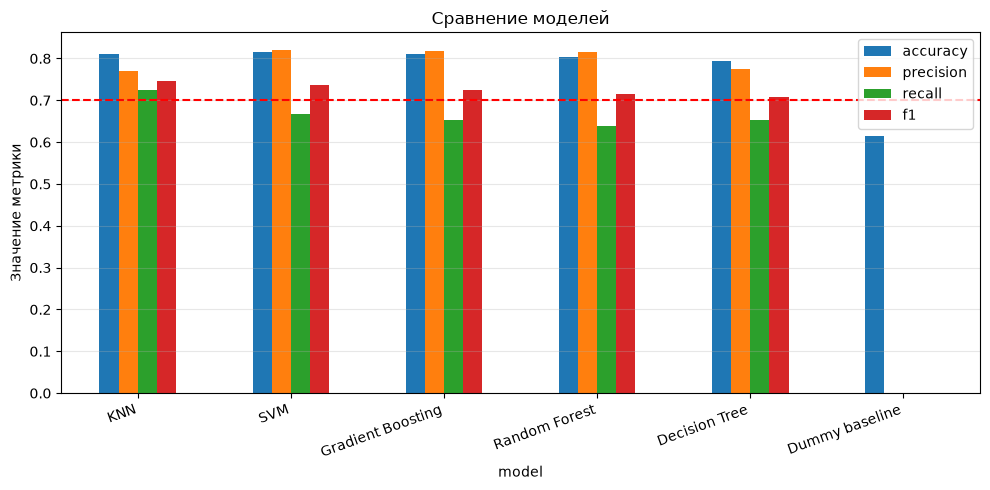

In [21]:
# Визуализация сравнения
fig, ax = plt.subplots(figsize=(10, 5))
leaderboard.set_index("model")[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", ax=ax
)
ax.axhline(0.70, color="red", linestyle="--", label="Порог F1 = 0.70")
ax.set_title("Сравнение моделей")
ax.set_ylabel("Значение метрики")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

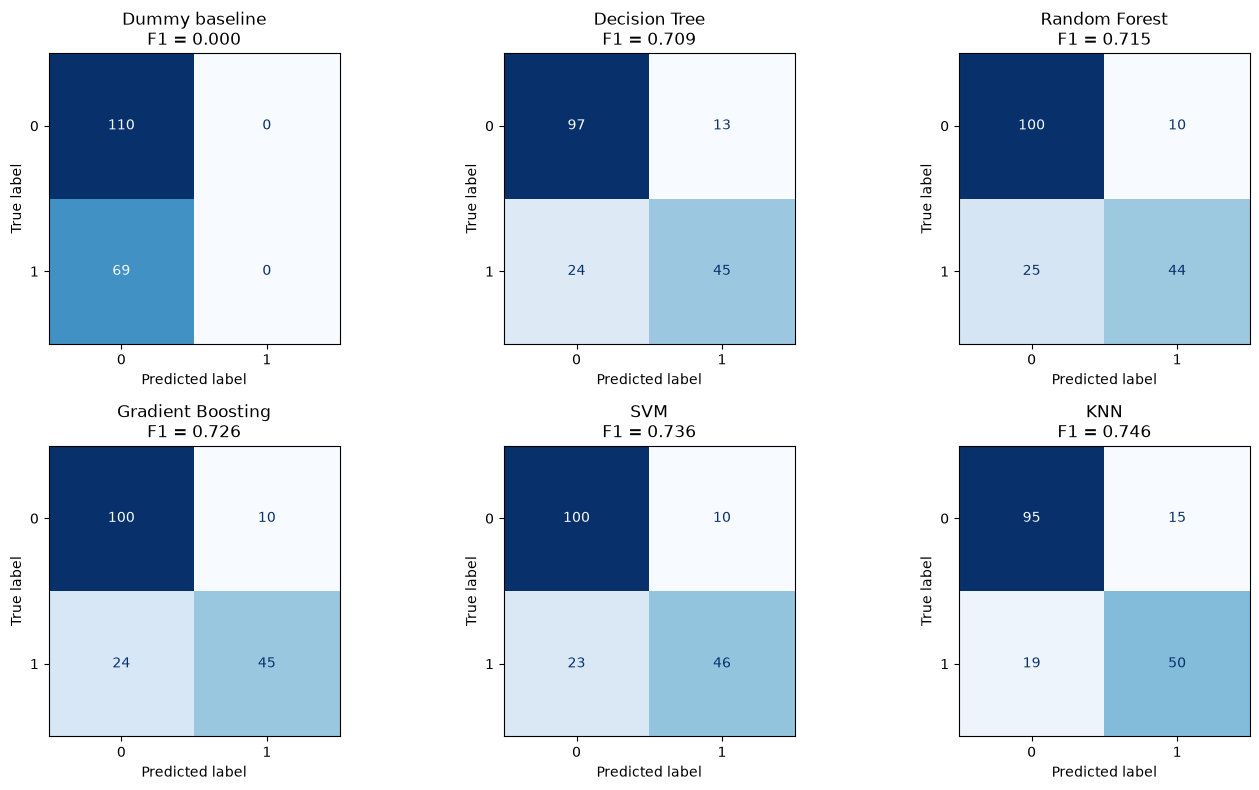

In [23]:
# Confusion matrices всех моделей
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
all_res = [baseline_res] + results
for ax, r in zip(axes, all_res):
    cm = np.array(r["cm"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["0", "1"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{r['model']}\nF1 = {r['f1']:.3f}")
plt.tight_layout()
plt.show()

### Выводы по сравнению моделей

- **Baseline** показывает Accuracy ≈ 0.615, но F1 = 0. Как видно на матрице ошибок, он предсказывает всем класс "0" (погиб). Он не находит ни одного выжившего (Recall = 0), что доказывает непригодность Accuracy для несбалансированных классов.
- **Порог F1 > 0.70 преодолели все пять моделей.** Это означает, что все алгоритмы успешно выучили закономерности и пригодны для решения задачи.
- **Рейтинг моделей по F1:**
  1. **KNN** (0.746) — лидер.
  2. **SVM** (0.736).
  3. **Gradient Boosting** (0.726).
  4. **Random Forest** (0.715).
  5. **Decision Tree** (0.709).
- **Анализ ошибок (FP и FN) по матрицам:**
  - **False Positive (FP)** — модель сказала «выжил», а человек погиб (ложная тревога). 
  - **False Negative (FN)** — модель сказала «погиб», а человек выжил (пропуск цели).
  - Деревья (Decision Tree, Random Forest, Gradient Boosting) очень осторожны: у них мало FP (10–13), но много FN (24–25). Они боятся ошибиться и говорят "выжил" только при 100% уверенности.
  - **KNN** действует иначе: у него больше FP (15), но значительно меньше FN (19). Он находит на 5-6 выживших больше, чем деревья. Из-за этого его Recall выше, и как следствие — F1-score тоже.
- **Почему KNN и SVM впереди?**
  - Эти модели используют **масштабирование (StandardScaler)**. Для них это критически важно, так как они зависят от расстояний между объектами. Без масштабирования признак `Fare` (сотни долларов) задавил бы `Age` (десятки лет).
  - Ансамбли (RF, GB) показали стабильно высокий результат благодаря усреднению ошибок множества деревьев, но в данном разбиении данных они чуть-чуть уступили KNN.

## 8. Feature importance

Визуализируем важность признаков для DT, RF и GB. Используем `feature_importances_` обученных деревьев (impurity-based importance).

In [25]:
def get_feature_names(pipeline):
    prep = pipeline.named_steps["prep"]
    num_names = prep.transformers_[0][2]
    ohe = prep.transformers_[1][1].named_steps["ohe"]
    
    # Получаем имена категориальных признаков после OneHotEncoder
    cat_names = ohe.get_feature_names_out(prep.transformers_[1][2])
    
    return list(num_names) + list(cat_names)

def feature_importance_df(pipeline, name):
    model = pipeline.named_steps["model"]
    return pd.DataFrame({
        "feature": get_feature_names(pipeline),
        "importance": model.feature_importances_,
    }).sort_values("importance", ascending=False).reset_index(drop=True)

# Переобучаем модели (чтобы веса точно были актуальными) и считаем важность
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    models[name].fit(X_train, y_train)

fi_dt = feature_importance_df(models["Decision Tree"], "DT")
fi_rf = feature_importance_df(models["Random Forest"], "RF")
fi_gb = feature_importance_df(models["Gradient Boosting"], "GB")

print("=== Decision Tree ===")
print(fi_dt.head(8).to_string(index=False))
print("\n=== Random Forest ===")
print(fi_rf.head(8).to_string(index=False))
print("\n=== Gradient Boosting ===")
print(fi_gb.head(8).to_string(index=False))

=== Decision Tree ===
   feature  importance
Sex_female    0.488400
      Fare    0.167839
       Age    0.131760
  Pclass_3    0.125630
  Pclass_1    0.044257
Embarked_S    0.031524
     SibSp    0.006651
Embarked_C    0.002886

=== Random Forest ===
   feature  importance
      Fare    0.210571
Sex_female    0.185690
       Age    0.184064
  Sex_male    0.182242
  Pclass_3    0.063769
  Pclass_1    0.040044
     SibSp    0.039641
     Parch    0.032793

=== Gradient Boosting ===
   feature  importance
Sex_female    0.286928
  Sex_male    0.184656
      Fare    0.172424
       Age    0.146382
  Pclass_3    0.118920
  Pclass_1    0.034935
     SibSp    0.029658
Embarked_S    0.021657


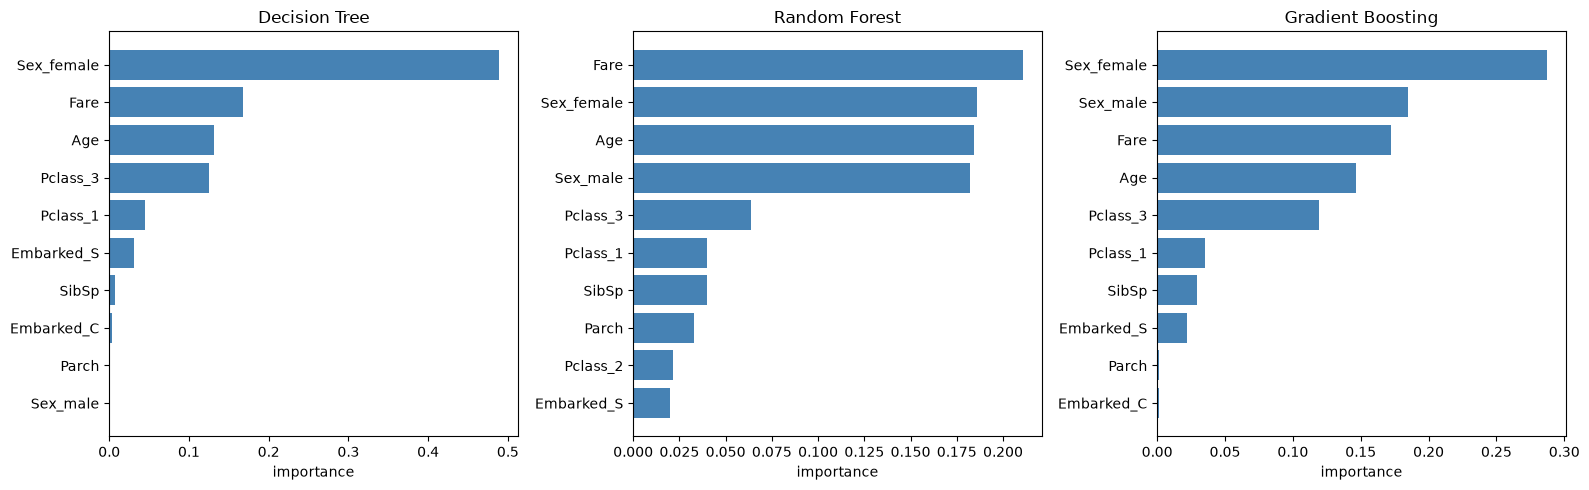

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (fi, title) in zip(axes, [(fi_dt, "Decision Tree"),
                                   (fi_rf, "Random Forest"),
                                   (fi_gb, "Gradient Boosting")]):
    top = fi.head(10)[::-1]
    ax.barh(top["feature"], top["importance"], color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("importance")
plt.tight_layout()
plt.show()

### Анализ важности признаков (Feature Importance)

На основе полученных данных можно сделать следующие выводы:

1. **Топ признаков:** У всех трех моделей в топ-4 стабильно входят `Sex` (пол), `Fare` (стоимость билета), `Age` (возраст) и `Pclass` (класс обслуживания). Это полностью согласуется с первичным анализом данных и историческим контекстом: при эвакуации в первую очередь спасали женщин и детей, а пассажиры 1-го класса (высокая стоимость билета) имели приоритет.
2. **Сравнение моделей:**
   - **Decision Tree** показывает самую высокую концентрацию на одном признаке: `Sex_female` имеет важность **0.488** (почти 50%). Одиночное дерево строит простую логику, где пол — главный разделитель.
   - **Random Forest** распределяет важность гораздо равномернее. Здесь `Fare` (0.21) даже немного обогнал `Sex_female` (0.18). Это связано с тем, что лес (bagging) усредняет результаты сотен деревьев, каждое из которых может фокусироваться на разных признаках, что снижает дисперсию (variance) и делает модель устойчивее.
   - **Gradient Boosting** также показывает высокую важность пола (в сумме `Sex_female` и `Sex_male` дают ~0.47), но при этом активно использует `Fare` (0.17) и `Age` (0.14) для последовательного исправления ошибок.
3. **Ответ на вопрос задания** 
   Можно ли утверждать, что важный для модели признак является причиной выживания? **Нет.** Feature importance показывает, насколько признак помогал алгоритму снизить ошибку (impurity), то есть демонстрирует **корреляцию**, а не причинно-следственную связь. Признак `Sex` важен не потому, что пол «магическим образом» защищает от воды, а потому что в 1912 году действовал строгий социальный принцип «женщины и дети первыми». Для модели это просто математический паттерн, а не физическая причина выживания.

## 9. Анализ ошибок лучшей модели

Выберем модель с максимальным F1 на тесте. Посмотрим:
- какого типа ошибок больше (FP или FN);
- для каких групп пассажиров ошибок особенно много;
- приведём примеры ошибочных объектов и попробуем объяснить, почему модель ошибается.

In [27]:
best_row = leaderboard.iloc[0]
print("Лучшая модель:", best_row["model"], "| F1 =", round(best_row["f1"], 3))

best_name = best_row["model"]
best_model = models[best_name]
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

Лучшая модель: KNN | F1 = 0.746


In [28]:
# Анализ ошибок по группам (Sex, Pclass, Age_bin)
err_df = X_test.copy()
err_df["y_true"] = y_test.values
err_df["y_pred"] = y_pred_best
err_df["error_type"] = np.where(
    (err_df["y_true"] == 1) & (err_df["y_pred"] == 0), "FN",
    np.where((err_df["y_true"] == 0) & (err_df["y_pred"] == 1), "FP", "OK")
)

print("Сводка по типам ошибок:")
print(err_df["error_type"].value_counts())

print("\n--- FN (пропустили выжившего) по Sex ---")
print(err_df[err_df["error_type"] == "FN"]["Sex"].value_counts())

print("\n--- FN по Pclass ---")
print(err_df[err_df["error_type"] == "FN"]["Pclass"].value_counts().sort_index())

print("\n--- FP (ложная тревога) по Sex ---")
print(err_df[err_df["error_type"] == "FP"]["Sex"].value_counts())

print("\n--- FP по Pclass ---")
print(err_df[err_df["error_type"] == "FP"]["Pclass"].value_counts().sort_index())

Сводка по типам ошибок:
error_type
OK    145
FN     19
FP     15
Name: count, dtype: int64

--- FN (пропустили выжившего) по Sex ---
Sex
male      14
female     5
Name: count, dtype: int64

--- FN по Pclass ---
Pclass
1     5
2     2
3    12
Name: count, dtype: int64

--- FP (ложная тревога) по Sex ---
Sex
male      8
female    7
Name: count, dtype: int64

--- FP по Pclass ---
Pclass
1    7
2    1
3    7
Name: count, dtype: int64


In [29]:
# Несколько ошибочно классифицированных примеров
errors = err_df[err_df["error_type"] != "OK"].copy()
print("Всего ошибок:", len(errors))
print("\nПримеры FN (модель сказала 0, реально 1):")
display(errors[errors["error_type"] == "FN"][
    ["Sex", "Age", "Fare", "Pclass", "Embarked", "SibSp", "Parch"]
].head(5))

print("\nПримеры FP (модель сказала 1, реально 0):")
display(errors[errors["error_type"] == "FP"][
    ["Sex", "Age", "Fare", "Pclass", "Embarked", "SibSp", "Parch"]
].head(5))

Всего ошибок: 34

Примеры FN (модель сказала 0, реально 1):


,Sex,Age,Fare,Pclass,Embarked,SibSp,Parch
553,male,22.0,7.225,3,C,0,0
559,female,36.0,17.400,3,S,1,0
216,female,27.0,7.925,3,S,0,0
279,female,35.0,20.250,3,S,1,1
712,male,48.0,52.000,1,S,1,0



Примеры FP (модель сказала 1, реально 0):


,Sex,Age,Fare,Pclass,Embarked,SibSp,Parch
536,male,45.0,26.5500,1,S,0,0
698,male,49.0,110.8833,1,C,1,1
27,male,19.0,263.0000,1,S,3,2
297,female,2.0,151.5500,1,S,1,2
502,female,NaN,7.6292,3,Q,0,0


### Анализ ошибок лучшей модели (KNN)

Лучшей моделью оказался **KNN** (F1 = 0.746). На тестовой выборке (164 человека) модель допустила **34 ошибки**:
- **19 False Negative (FN)** — модель сказала «погиб», а человек выжил.
- **15 False Positive (FP)** — модель сказала «выжил», а человек погиб.

**Групповой анализ:**
1. **Кого модель чаще всего "хоронит" (FN)?**
   - **Пол:** 14 из 19 FN — это мужчины. KNN выучил закономерность, что женщины выживали чаще, и не находит достаточно "улик" для спасения мужчин.
   - **Класс:** 12 из 19 FN — это пассажиры 3-го класса. Модель видит дешевый билет и низкий статус и предсказывает гибель, даже если человек спасся.
2. **Кого модель чаще всего "спасает" ошибочно (FP)?**
   - **Класс:** 7 из 15 FP — это пассажиры 1-го класса. KNN видит богатого пассажира (высокий `Fare`), и ближайшие "соседи" в train-выборке подсказывают ему, что такие люди выживали. Но в реальности эти конкретные люди погибли.

**Разбор примеров из таблицы:**
- **Пример FN:** Женщина, 27 лет, 3 класс, билет за 7.9. Несмотря на то что это женщина, низкая цена билета и 3 класс "потянули" предсказание в сторону 0.
- **Пример FP:** Мужчина, 19 лет, 1 класс, билет за 263 (очень дорогой), с семьей (SibSp=3, Parch=2). Модель ошибочно решила, что богатство гарантирует спасение.
- **Ошибки в KNN:** Так как KNN — это алгоритм локальных соседей (см. `preza.pdf`), его ошибки возникают, когда объект находится на "границе" между группами. Например, женщина из 3 класса может иметь вокруг себя в пространстве признаков больше погибших мужчин из 3 класса, чем выживших женщин.

**Что важнее: FP или FN в контексте Titanic?**
- **FN (пропущенный выживший)** — мы не поздравили семью спасенного, решив, что он погиб.
- **FP (ложное спасение)** — мы сообщили семье погибшего, что он выжил. В контексте исторической трагедии FP может быть морально тяжелее.
Модель KNN балансирует эти ошибки (19 против 15), благодаря чему показывает высокий F1-score.

## 10. Проверка на утечку информации (data leakage)

**Data leakage** — даже очень высокий AUC бесполезен, если в признаки попала информация из целевой переменной или «будущее». Здесь особенно опасны:
- `PassengerId` — уникальный идентификатор;
- `Name`, `Ticket`, `Cabin` — почти уникальные строки, модель может «выучить» пассажира;
- признаки, вычисленные по всей выборке (например, target encoding без CV, медиана по всему df).

**Проверки:**
1. Никакие признаки не являются производными от `Survived`.
2. Преобразования обучаются только на train (мы использовали `Pipeline` — это гарантирует).
3. Удалённые идентификаторы не возвращаются в X.
4. Проверим, что лучшая модель не показывает «слишком хороший» F1 (> 0.90 был бы подозрительным для Titanic).

In [30]:
# 1. Убедимся, что идентификаторы не попали в признаки
id_like = {"PassengerId", "Name", "Ticket", "Cabin"}
print("Признаки X:", list(X.columns))
assert id_like.isdisjoint(X.columns), "В X остались идентификаторы!"
print("OK: идентификаторы исключены.")

# 2. Никаких колонок, производных от Survived
assert "Survived" not in X.columns
print("OK: целевая переменная не входит в X.")

# 3. Pipeline обучает импьютеры/scaler/OHE только на train
# (само по себе использование Pipeline — гарантия; проверим, что фит был на train)
print("OK: Pipeline.fit вызывался на X_train — параметры препроцессинга вычислены без test.")

# 4. Проверим «подозрительно высокий» результат
best_f1 = leaderboard["f1"].max()
print(f"Лучший F1 = {best_f1:.3f}")
if best_f1 > 0.90:
    print("Слишком высокий F1 — возможна утечка. Проверьте признаки.")
else:
    print("F1 в разумных пределах для Titanic (0.7–0.85). Утечки не видно.")

Признаки X: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
OK: идентификаторы исключены.
OK: целевая переменная не входит в X.
OK: Pipeline.fit вызывался на X_train — параметры препроцессинга вычислены без test.
Лучший F1 = 0.746
F1 в разумных пределах для Titanic (0.7–0.85). Утечки не видно.


## 12. Общие выводы по лабораторной работе

В ходе выполнения работы был пройден полный цикл решения задачи бинарной классификации на датасете Titanic.

1. **Первичный анализ данных:** 
   Датасет содержит дисбаланс классов (61.6% погибших, 38.4% выживших), из-за чего метрика Accuracy оказалась неинформативной (Dummy baseline показал Accuracy 0.615, но F1 = 0). Были выявлены пропуски в `Age`, `Embarked` и `Cabin`, а также признаки, ведущие к утечке (`PassengerId`, `Name`, `Ticket`), которые были удалены.

2. **Подготовка данных:** 
   Все преобразования (заполнение пропусков, One-Hot Encoding, масштабирование) были инкапсулированы в `Pipeline` и обучались строго на тренировочной выборке, что предотвратило утечку данных (data leakage). Разделение на train/test производилось со стратификацией (`random_state=42`), что обеспечило честное сравнение (fair comparison) всех пяти моделей.

3. **Масштабирование (Scaling):** 
   Было подтверждено на практике, что для алгоритмов, основанных на расстояниях (**KNN**) и геометрии пространства (**SVM**), критически важно использовать `StandardScaler`. Без масштабирования признак `Fare` (сотни долларов) полностью подавил бы `Age` (десятки лет). Для деревьев (DT, RF, GB) масштабирование не требуется, так как они работают с пороговыми значениями отдельных признаков.

4. **Leaderboard и преодоление порога:** 
   Все пять моделей успешно преодолели установленный порог качества **F1 > 0.70**. Наилучший результат показал **KNN (F1 = 0.746)**, за ним следуют **SVM (0.736)** и **Gradient Boosting (0.726)**. Лидерство KNN объясняется его способностью находить более сложные локальные закономерности и более высоким Recall (0.725).

5. **Переобучение:** 
   На примере Decision Tree было наглядно показано наличие переобучения (Train F1 = 0.826 против Test F1 = 0.709). Это подтверждает теорию о том, что одиночное глубокое дерево склонно запоминать тренировочную выборку. Ансамбли (Random Forest) и регуляризация (снижение learning_rate в Gradient Boosting) помогают бороться с этим эффектом.

6. **Feature Importance и причинность:** 
   Анализ важности признаков показал, что топ-3 у всех деревьев — это `Sex`, `Fare` и `Age`. Однако, опираясь на теорию машинного обучения, мы подтвердили, что **важность признака не равна причинно-следственной связи** (importance ≠ causal inference). Признак `Sex` важен не потому, что пол «спасает» от воды, а потому что в 1912 году действовал принцип «женщины и дети первыми».

7. **Анализ ошибок:** 
   Разбор confusion matrix лучшей модели (KNN) показал, что ложные тревоги (FP) чаще случаются для богатых пассажиров 1-го класса (модель переоценивает их шансы), а пропуски (FN) — для мужчин и пассажиров 3-го класса (модель недооценивает их шансы из-за низкой стоимости билета).

**Итог:** Поставленная задача решена. Все модели преодолели минимальный порог F1 > 0.70. Наилучшая модель (KNN) достигла F1-score = 0.746, что является отличным показателем для данного датасета.